In [ ]:
data = pd.read_csv("smart_city_traffic_mobility.csv")
df = pd.DataFrame(data)
df

,record_id,city_zone,road_id,intersection_id,latitude,longitude,road_type,lanes,speed_limit,vehicle_count,...,traffic_camera_count,iot_sensor_health,signal_cycle_seconds,green_light_duration,emergency_vehicle_detected,traffic_flow_rate,congestion_score,emission_estimate,fuel_waste_estimate,congestion_level
0,REC_0000001,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,...,1,Optimal,60,18,0,162.0,16.8,39.14,8.53,Low
1,REC_0000002,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,150,...,1,Optimal,60,18,0,150.0,18.4,36.09,7.83,Low
2,REC_0000003,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,186,...,1,Optimal,60,18,0,186.0,20.7,44.01,9.39,Low
3,REC_0000004,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,162,...,1,Optimal,60,18,0,162.0,17.8,38.47,8.24,Low
4,REC_0000005,Financial District,RD_206,INT_001,40.757551,-73.990504,Local Street,2,40,168,...,1,Optimal,60,18,0,168.0,17.3,40.28,8.71,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203995,REC_0203996,Residential West,RD_281,INT_100,40.665597,-74.039096,Local Street,2,40,224,...,3,Optimal,60,19,0,224.0,22.5,53.10,11.35,Low
203996,REC_0203997,Residential West,RD_281,INT_100,40.665597,-74.039096,Local Street,2,40,125,...,3,Optimal,60,18,0,125.0,16.6,29.62,6.33,Low
203997,REC_0203998,Residential West,RD_281,INT_100,40.665597,-74.039096,Local Street,2,40,111,...,3,Optimal,60,18,0,111.0,23.0,28.54,6.59,Low
203998,REC_0203999,Residential West,RD_281,INT_100,40.665597,-74.039096,Local Street,2,40,100,...,3,Optimal,60,18,0,100.0,12.2,25.74,5.95,Low


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df.shape

(204000, 47)

In [ ]:
df.columns

Index(['record_id', 'city_zone', 'road_id', 'intersection_id', 'latitude',
       'longitude', 'road_type', 'lanes', 'speed_limit', 'vehicle_count',
       'average_speed', 'heavy_vehicle_count', 'motorcycle_count',
       'public_transport_count', 'traffic_density', 'queue_length',
       'average_wait_time', 'timestamp', 'hour', 'day_of_week', 'is_weekend',
       'is_holiday', 'rush_hour', 'peak_period', 'temperature', 'rainfall_mm',
       'visibility_km', 'air_quality_index', 'weather_condition',
       'nearby_school', 'nearby_hospital', 'nearby_market',
       'construction_activity', 'road_condition', 'parking_occupancy',
       'public_event', 'accident_reported', 'traffic_camera_count',
       'iot_sensor_health', 'signal_cycle_seconds', 'green_light_duration',
       'emergency_vehicle_detected', 'traffic_flow_rate', 'congestion_score',
       'emission_estimate', 'fuel_waste_estimate', 'congestion_level'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204000 entries, 0 to 203999
Data columns (total 47 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   record_id                   204000 non-null  object 
 1   city_zone                   204000 non-null  object 
 2   road_id                     204000 non-null  object 
 3   intersection_id             204000 non-null  object 
 4   latitude                    204000 non-null  float64
 5   longitude                   204000 non-null  float64
 6   road_type                   204000 non-null  object 
 7   lanes                       204000 non-null  int64  
 8   speed_limit                 204000 non-null  int64  
 9   vehicle_count               204000 non-null  int64  
 10  average_speed               204000 non-null  float64
 11  heavy_vehicle_count         204000 non-null  int64  
 12  motorcycle_count            204000 non-null  int64  
 13  public_transpo

In [ ]:
df.describe()

,latitude,longitude,lanes,speed_limit,vehicle_count,average_speed,heavy_vehicle_count,motorcycle_count,public_transport_count,traffic_density,...,public_event,accident_reported,traffic_camera_count,signal_cycle_seconds,green_light_duration,emergency_vehicle_detected,traffic_flow_rate,congestion_score,emission_estimate,fuel_waste_estimate
count,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,...,204000.000000,204000.00000,204000.00000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.00000
mean,40.716219,-74.004859,2.750000,56.700000,749.585907,42.235582,36.969373,74.478319,21.959971,90.660393,...,0.039309,0.01975,2.37000,75.174118,39.070775,0.020049,749.585907,50.007555,257.416941,72.49638
std,0.044876,0.044211,0.726294,17.609984,754.542368,22.214697,41.987095,81.489370,25.773987,85.277658,...,0.194329,0.13914,1.12832,26.080578,27.153351,0.140168,754.542368,38.798606,339.096417,111.51992
min,40.636691,-74.083673,2.000000,40.000000,54.000000,5.000000,1.000000,3.000000,0.000000,9.000000,...,0.000000,0.00000,1.00000,60.000000,18.000000,0.000000,54.000000,5.400000,12.740000,2.71000
25%,40.676753,-74.041839,2.000000,40.000000,171.000000,27.700000,7.000000,16.000000,4.000000,20.800000,...,0.000000,0.00000,1.00000,60.000000,18.000000,0.000000,171.000000,15.200000,41.250000,8.95000
50%,40.721824,-74.001825,3.000000,60.000000,308.000000,40.000000,16.000000,32.000000,9.000000,35.700000,...,0.000000,0.00000,2.00000,60.000000,23.000000,0.000000,308.000000,25.100000,74.070000,16.02000
75%,40.753293,-73.972532,3.000000,60.000000,1208.000000,58.100000,56.000000,117.000000,33.000000,175.100000,...,0.000000,0.00000,3.00000,120.000000,84.000000,0.000000,1208.000000,100.000000,376.840000,98.48000
max,40.790642,-73.928036,4.000000,90.000000,3162.000000,90.000000,246.000000,468.000000,156.000000,378.500000,...,1.000000,1.00000,4.00000,120.000000,84.000000,1.000000,3162.000000,100.000000,9717.220000,4066.07000


In [ ]:
df.dtypes

,0
record_id,object
city_zone,object
road_id,object
intersection_id,object
latitude,float64
longitude,float64
road_type,object
lanes,int64
speed_limit,int64
vehicle_count,int64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
record_id,0
city_zone,0
road_id,0
intersection_id,0
latitude,0
longitude,0
road_type,0
lanes,0
speed_limit,0
vehicle_count,0


In [ ]:
df = df.drop(["record_id","road_id","intersection_id","timestamp","congestion_score"],axis=1)
df

,city_zone,latitude,longitude,road_type,lanes,speed_limit,vehicle_count,average_speed,heavy_vehicle_count,motorcycle_count,...,accident_reported,traffic_camera_count,iot_sensor_health,signal_cycle_seconds,green_light_duration,emergency_vehicle_detected,traffic_flow_rate,emission_estimate,fuel_waste_estimate,congestion_level
0,Financial District,40.757551,-73.990504,Local Street,2,40,162,40.0,12,9,...,0,1,Optimal,60,18,0,162.0,39.14,8.53,Low
1,Financial District,40.757551,-73.990504,Local Street,2,40,150,37.7,8,12,...,0,1,Optimal,60,18,0,150.0,36.09,7.83,Low
2,Financial District,40.757551,-73.990504,Local Street,2,40,186,38.4,13,12,...,0,1,Optimal,60,18,0,186.0,44.01,9.39,Low
3,Financial District,40.757551,-73.990504,Local Street,2,40,162,38.9,7,11,...,0,1,Optimal,60,18,0,162.0,38.47,8.24,Low
4,Financial District,40.757551,-73.990504,Local Street,2,40,168,40.0,8,12,...,0,1,Optimal,60,18,0,168.0,40.28,8.71,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203995,Residential West,40.665597,-74.039096,Local Street,2,40,224,40.0,5,28,...,0,3,Optimal,60,19,0,224.0,53.10,11.35,Low
203996,Residential West,40.665597,-74.039096,Local Street,2,40,125,36.8,4,16,...,0,3,Optimal,60,18,0,125.0,29.62,6.33,Low
203997,Residential West,40.665597,-74.039096,Local Street,2,40,111,32.0,4,12,...,0,3,Optimal,60,18,0,111.0,28.54,6.59,Low
203998,Residential West,40.665597,-74.039096,Local Street,2,40,100,39.8,4,10,...,0,3,Optimal,60,18,0,100.0,25.74,5.95,Low


In [ ]:
drop_columns = [
    "traffic_density",
    "queue_length",
    "average_wait_time",
    "traffic_flow_rate",
    "emission_estimate",
    "fuel_waste_estimate",
    "vehicle_count",
    "average_speed"
]

df = df.drop(columns=drop_columns)

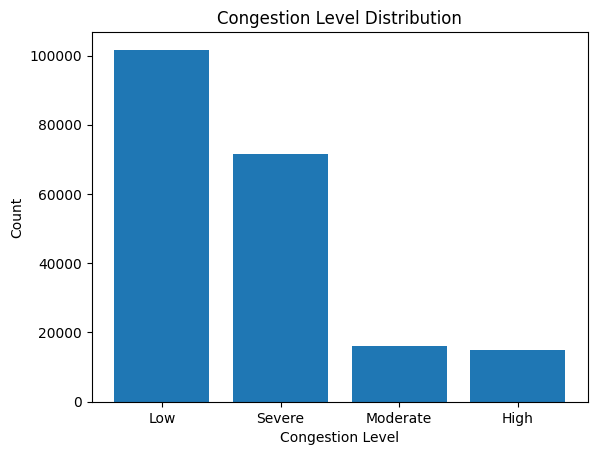

,count
congestion_level,
Low,101679
Severe,71497
Moderate,15976
High,14848


In [ ]:
df_1 = df["congestion_level"].value_counts()
plt.bar(df_1.index, df_1.values)
plt.xlabel("Congestion Level")
plt.ylabel("Count")
plt.title("Congestion Level Distribution")
plt.show()
df_1

In [ ]:
# Numeric columns
numerical_columns = df.select_dtypes(include="number").columns
numerical_columns

Index(['latitude', 'longitude', 'lanes', 'speed_limit', 'heavy_vehicle_count',
       'motorcycle_count', 'public_transport_count', 'hour', 'day_of_week',
       'is_weekend', 'is_holiday', 'rush_hour', 'temperature', 'rainfall_mm',
       'visibility_km', 'air_quality_index', 'nearby_school',
       'nearby_hospital', 'nearby_market', 'construction_activity',
       'parking_occupancy', 'public_event', 'accident_reported',
       'traffic_camera_count', 'signal_cycle_seconds', 'green_light_duration',
       'emergency_vehicle_detected'],
      dtype='object')

In [ ]:
corr_columns = ["lanes", "motorcycle_count", "heavy_vehicle_count",
                "public_transport_count", "day_of_week", "is_weekend",
                "is_holiday", "rush_hour", "green_light_duration",
                "signal_cycle_seconds", "public_event", "construction_activity"]

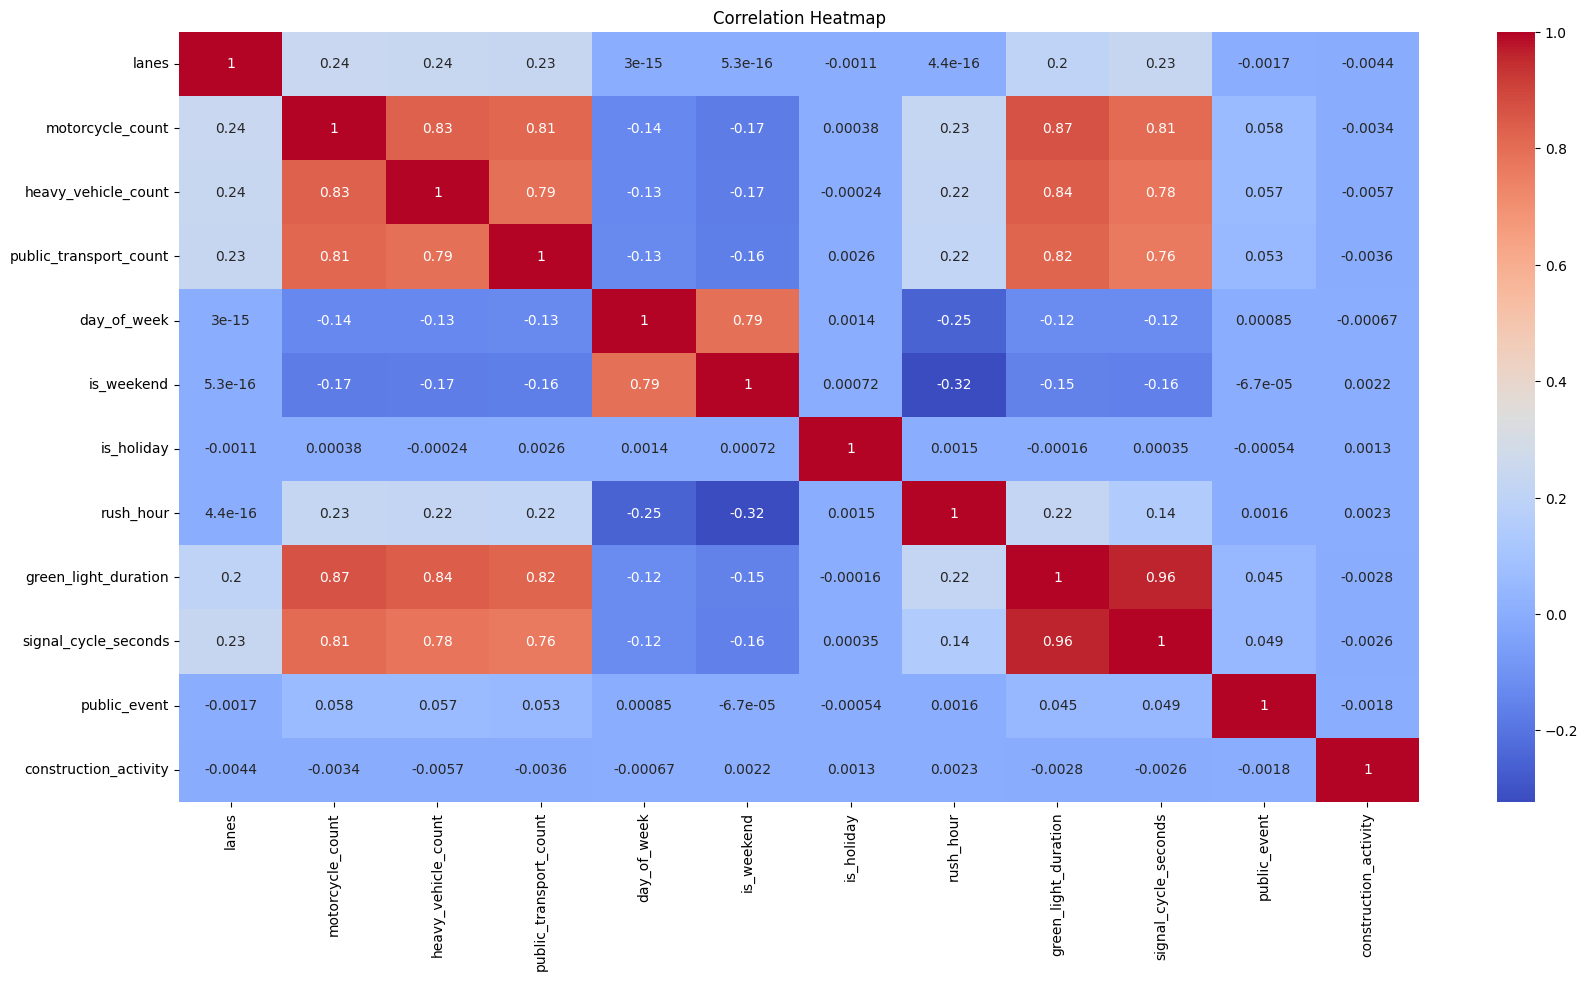

In [ ]:
plt.figure(figsize=(20, 10))
sns.heatmap(df[corr_columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
list = ["city_zone","road_type","peak_period","weather_condition","road_condition"]
df_2 = pd.get_dummies(df[list])
df_2

,city_zone_Downtown Core,city_zone_Financial District,city_zone_Industrial East,city_zone_Residential West,city_zone_Suburban North,city_zone_Tech Park,road_type_Arterial,road_type_Collector,road_type_Highway,road_type_Local Street,...,peak_period_Morning Peak,peak_period_Night,peak_period_Off-Peak,weather_condition_Clear,weather_condition_Fog,weather_condition_Heavy Rain,weather_condition_Rain,road_condition_Good,road_condition_Poor,road_condition_Wet
0,False,True,False,False,False,False,False,False,False,True,...,False,True,False,True,False,False,False,False,True,False
1,False,True,False,False,False,False,False,False,False,True,...,False,True,False,True,False,False,False,True,False,False
2,False,True,False,False,False,False,False,False,False,True,...,False,True,False,True,False,False,False,True,False,False
3,False,True,False,False,False,False,False,False,False,True,...,False,True,False,True,False,False,False,True,False,False
4,False,True,False,False,False,False,False,False,False,True,...,False,True,False,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203995,False,False,False,True,False,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
203996,False,False,False,True,False,False,False,False,False,True,...,False,False,True,True,False,False,False,True,False,False
203997,False,False,False,True,False,False,False,False,False,True,...,False,False,True,False,False,False,True,False,False,True
203998,False,False,False,True,False,False,False,False,False,True,...,False,True,False,True,False,False,False,True,False,False


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
X = pd.concat([df[numerical_columns],df_2],axis=1)
X

,latitude,longitude,lanes,speed_limit,heavy_vehicle_count,motorcycle_count,public_transport_count,hour,day_of_week,is_weekend,...,peak_period_Morning Peak,peak_period_Night,peak_period_Off-Peak,weather_condition_Clear,weather_condition_Fog,weather_condition_Heavy Rain,weather_condition_Rain,road_condition_Good,road_condition_Poor,road_condition_Wet
0,40.757551,-73.990504,2,40,12,9,7,0,3,0,...,False,True,False,True,False,False,False,False,True,False
1,40.757551,-73.990504,2,40,8,12,5,1,3,0,...,False,True,False,True,False,False,False,True,False,False
2,40.757551,-73.990504,2,40,13,12,6,2,3,0,...,False,True,False,True,False,False,False,True,False,False
3,40.757551,-73.990504,2,40,7,11,7,3,3,0,...,False,True,False,True,False,False,False,True,False,False
4,40.757551,-73.990504,2,40,8,12,6,4,3,0,...,False,True,False,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203995,40.665597,-74.039096,2,40,5,28,5,19,3,0,...,False,False,False,True,False,False,False,True,False,False
203996,40.665597,-74.039096,2,40,4,16,3,20,3,0,...,False,False,True,True,False,False,False,True,False,False
203997,40.665597,-74.039096,2,40,4,12,2,21,3,0,...,False,False,True,False,False,False,True,False,False,True
203998,40.665597,-74.039096,2,40,4,10,2,22,3,0,...,False,True,False,True,False,False,False,True,False,False


In [ ]:
y = df["congestion_level"]
y

,congestion_level
0,Low
1,Low
2,Low
3,Low
4,Low
...,...
203995,Low
203996,Low
203997,Low
203998,Low


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_minmax = scaler.fit_transform(X_train)
X_test_minmax = scaler.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

models = [KNeighborsClassifier(),GaussianNB(),MultinomialNB(),BernoulliNB(),DecisionTreeClassifier(),RandomForestClassifier(n_estimators=100,criterion='gini')]

for model in models:

    if isinstance(model, KNeighborsClassifier):
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    elif isinstance(model, MultinomialNB):
        model.fit(X_train_minmax, y_train)
        y_pred = model.predict(X_test_minmax)

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    print("\nModel:", model)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("Classification Report:")
    print(classification_report(y_test, y_pred))


Model: KNeighborsClassifier()
Accuracy: 0.9274264705882352
Confusion Matrix:
[[ 2380   114   292   184]
 [   46 19751   502    37]
 [  150   962  2033    50]
 [  355   139   130 13675]]
Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.80      0.81      2970
         Low       0.94      0.97      0.96     20336
    Moderate       0.69      0.64      0.66      3195
      Severe       0.98      0.96      0.97     14299

    accuracy                           0.93     40800
   macro avg       0.86      0.84      0.85     40800
weighted avg       0.93      0.93      0.93     40800


Model: GaussianNB()
Accuracy: 0.8459068627450981
Confusion Matrix:
[[ 1206     0  1547   217]
 [    0 18261  2075     0]
 [   77   231  2887     0]
 [ 1562     0   578 12159]]
Classification Report:
              precision    recall  f1-score   support

        High       0.42      0.41      0.41      2970
         Low       0.99      0.90      0.94   

In [ ]:
print(df.columns.tolist())

['city_zone', 'latitude', 'longitude', 'road_type', 'lanes', 'speed_limit', 'heavy_vehicle_count', 'motorcycle_count', 'public_transport_count', 'hour', 'day_of_week', 'is_weekend', 'is_holiday', 'rush_hour', 'peak_period', 'temperature', 'rainfall_mm', 'visibility_km', 'air_quality_index', 'weather_condition', 'nearby_school', 'nearby_hospital', 'nearby_market', 'construction_activity', 'road_condition', 'parking_occupancy', 'public_event', 'accident_reported', 'traffic_camera_count', 'iot_sensor_health', 'signal_cycle_seconds', 'green_light_duration', 'emergency_vehicle_detected', 'congestion_level']
